# Laboratorium 2 – sieć samoorganizująca SOM (część druga)

## 1. Dane, normalizacja i funkcje z labu 1

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

iris = load_iris()
X = iris.data
y = iris.target
nazwy_klas = list(iris.target_names)

X_norm = np.zeros(X.shape)
for kolumna in range(4):
    minimum = X[:, kolumna].min()
    maksimum = X[:, kolumna].max()
    X_norm[:, kolumna] = (X[:, kolumna] - minimum) / (maksimum - minimum)

print("Dane:", X_norm.shape)

Dane: (150, 4)


In [2]:
def odleglosc(x, w):
    suma = 0
    for i in range(len(x)):
        suma = suma + (x[i] - w[i]) ** 2
    return suma ** 0.5


def znajdz_zwyciezce(x, wagi):
    najlepszy = 0
    najmniejsza = odleglosc(x, wagi[0])
    for n in range(1, len(wagi)):
        d = odleglosc(x, wagi[n])
        if d < najmniejsza:
            najmniejsza = d
            najlepszy = n
    return najlepszy


def aktualizuj_wagi(x, wagi, numer_zwyciezcy, alfa):
    for i in range(len(x)):
        wagi[numer_zwyciezcy][i] = wagi[numer_zwyciezcy][i] + alfa * (x[i] - wagi[numer_zwyciezcy][i])

## 2. Współczynnik uczenia malejący z epokami

In [3]:
def alfa_stala(alfa0, t, T):
    return alfa0

def alfa_liniowa(alfa0, t, T):
    return alfa0 * (1 - t / T)

def alfa_wykladnicza(alfa0, t, T):
    return alfa0 * np.exp(-3 * t / T)

def alfa_odwrotna(alfa0, t, T):
    return alfa0 / (1 + 5 * t / T)

funkcje_alfa = {
    "stała": alfa_stala,
    "liniowa": alfa_liniowa,
    "wykładnicza": alfa_wykladnicza,
    "odwrotna": alfa_odwrotna,
}

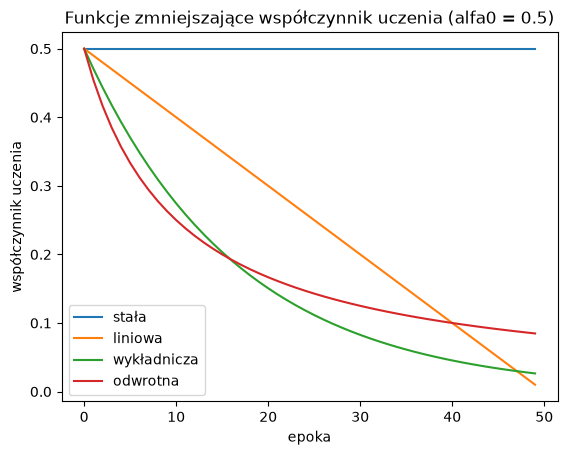

In [4]:
T = 50
epoki = list(range(T))

for nazwa in funkcje_alfa:
    funkcja = funkcje_alfa[nazwa]
    wartosci = [funkcja(0.5, t, T) for t in epoki]
    plt.plot(epoki, wartosci, label=nazwa)

plt.xlabel("epoka")
plt.ylabel("współczynnik uczenia")
plt.title("Funkcje zmniejszające współczynnik uczenia (alfa0 = 0.5)")
plt.legend()
plt.show()

## 3. Uczenie sieci

In [5]:
def ucz_som(dane, liczba_epok=50, alfa0=0.5, funkcja_alfa=alfa_liniowa,
            ziarno=42, wypisuj=True):
    rng = np.random.RandomState(ziarno)

    numery = rng.permutation(len(dane))[:3]
    wagi = dane[numery].copy()

    for epoka in range(liczba_epok):
        alfa = funkcja_alfa(alfa0, epoka, liczba_epok)

        if wypisuj and epoka % 10 == 0:
            print("Epoka", epoka, " alfa =", round(alfa, 4))

        kolejnosc = rng.permutation(len(dane))

        for i in kolejnosc:
            x = dane[i]
            zwyciezca = znajdz_zwyciezce(x, wagi)
            aktualizuj_wagi(x, wagi, zwyciezca, alfa)

    return wagi

In [6]:
wagi_koncowe = ucz_som(X_norm, liczba_epok=50, alfa0=0.5, funkcja_alfa=alfa_liniowa)

print()
print("Końcowe wagi 3 neuronów:")
print(wagi_koncowe.round(3))

Epoka 0  alfa = 0.5
Epoka 10  alfa = 0.4
Epoka 20  alfa = 0.3
Epoka 30  alfa = 0.2
Epoka 40  alfa = 0.1

Końcowe wagi 3 neuronów:
[[0.445 0.309 0.576 0.546]
 [0.192 0.587 0.078 0.06 ]
 [0.708 0.455 0.797 0.825]]


## 4. Przypisanie przykładów do neuronów

Dla każdego z 150 przykładów sprawdzamy, który neuron wygrywa.

In [7]:
def przypisz_przyklady(dane, wagi):
    przypisania = []
    for i in range(len(dane)):
        przypisania.append(znajdz_zwyciezce(dane[i], wagi))
    return przypisania

przypisania = przypisz_przyklady(X_norm, wagi_koncowe)

print("Liczba przypisań:", len(przypisania))
print("Pierwsze 20 przypisań:", przypisania[:20])

Liczba przypisań: 150
Pierwsze 20 przypisań: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


## 5. Macierz neuron × klasa

In [8]:
def macierz_przypisan(przypisania, etykiety):
    macierz = np.zeros((3, 3), dtype=int)
    for i in range(len(przypisania)):
        neuron = przypisania[i]
        klasa = etykiety[i]
        macierz[neuron][klasa] = macierz[neuron][klasa] + 1
    return macierz

macierz = macierz_przypisan(przypisania, y)

tabela = pd.DataFrame(macierz,
                      index=["N1", "N2", "N3"],
                      columns=[k.capitalize() for k in nazwy_klas])
tabela.index.name = "Neuron"
tabela

,Setosa,Versicolor,Virginica
Neuron,,,
N1,0,47,14
N2,50,0,0
N3,0,3,36


In [9]:
print("Suma wszystkich komórek:", macierz.sum())

Suma wszystkich komórek: 150


### Jak ocenić jakość?

In [10]:
def ocen(macierz):
    suma_najwiekszych = 0
    zajete_gatunki = []
    for n in range(3):
        najwiekszy = macierz[n].max()
        suma_najwiekszych = suma_najwiekszych + najwiekszy
        gatunek = int(np.argmax(macierz[n]))
        if gatunek not in zajete_gatunki:
            zajete_gatunki.append(gatunek)
    trafnosc = suma_najwiekszych / macierz.sum()
    return trafnosc, len(zajete_gatunki)

trafnosc, ile_gatunkow = ocen(macierz)
print("Trafność:", round(trafnosc * 100, 1), "%")
print("Liczba różnych gatunków pokrytych przez neurony:", ile_gatunkow, "z 3")

Trafność: 88.7 %
Liczba różnych gatunków pokrytych przez neurony: 3 z 3


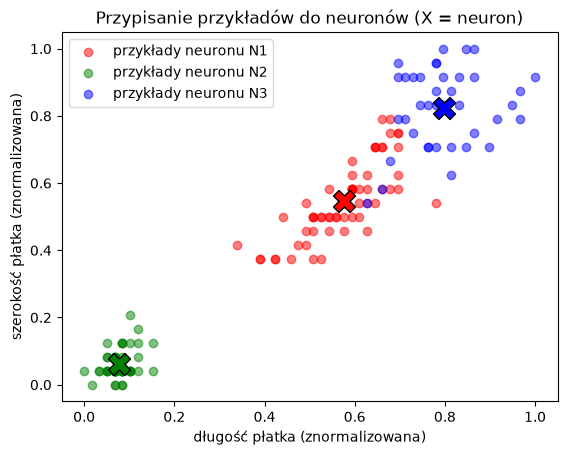

In [11]:
kolory = ["red", "green", "blue"]
for n in range(3):
    punkty = [i for i in range(150) if przypisania[i] == n]
    plt.scatter(X_norm[punkty, 2], X_norm[punkty, 3], color=kolory[n],
                alpha=0.5, label="przykłady neuronu N" + str(n + 1))
    plt.scatter(wagi_koncowe[n, 2], wagi_koncowe[n, 3], color=kolory[n],
                marker="X", s=250, edgecolors="black")

plt.xlabel("długość płatka (znormalizowana)")
plt.ylabel("szerokość płatka (znormalizowana)")
plt.title("Przypisanie przykładów do neuronów (X = neuron)")
plt.legend()
plt.show()

## 6. Eksperymenty

In [12]:
def eksperyment(liczba_epok, alfa0, funkcja_alfa, powtorzenia=10):
    trafnosci = []
    for p in range(powtorzenia):
        w = ucz_som(X_norm, liczba_epok, alfa0, funkcja_alfa, ziarno=p, wypisuj=False)
        przyp = przypisz_przyklady(X_norm, w)
        m = macierz_przypisan(przyp, y)
        tr, gat = ocen(m)
        trafnosci.append(tr)
    return np.mean(trafnosci), np.min(trafnosci), np.max(trafnosci)

### 6.1 Różna liczba epok

In [13]:
wyniki = []
for epoki in [1, 5, 10, 25, 50, 100, 200]:
    sr, mn, mx = eksperyment(epoki, 0.5, alfa_liniowa)
    wyniki.append([epoki, round(sr * 100, 1), round(mn * 100, 1), round(mx * 100, 1)])

tab_epoki = pd.DataFrame(wyniki, columns=["epoki", "średnia trafność %", "min %", "max %"])
tab_epoki

,epoki,średnia trafność %,min %,max %
0,1,83.1,66.7,90.0
1,5,88.6,86.7,90.7
2,10,88.7,88.7,88.7
3,25,88.7,88.7,88.7
4,50,88.7,88.7,88.7
5,100,88.7,88.7,88.7
6,200,88.7,88.7,88.7


### 6.2 Różny początkowy współczynnik uczenia

In [14]:
wyniki = []
for a0 in [0.01, 0.05, 0.1, 0.3, 0.5, 0.9]:
    sr, mn, mx = eksperyment(50, a0, alfa_liniowa)
    wyniki.append([a0, round(sr * 100, 1), round(mn * 100, 1), round(mx * 100, 1)])

tab_alfa = pd.DataFrame(wyniki, columns=["alfa0", "średnia trafność %", "min %", "max %"])
tab_alfa

,alfa0,średnia trafność %,min %,max %
0,0.01,79.8,66.7,88.7
1,0.05,79.9,66.7,88.7
2,0.10,88.7,88.7,88.7
3,0.30,88.7,88.7,88.7
4,0.50,88.7,88.7,88.7
5,0.90,88.7,88.7,88.7


### 6.3 Różne funkcje zmniejszające współczynnik

In [15]:
wyniki = []
for nazwa in funkcje_alfa:
    sr, mn, mx = eksperyment(50, 0.5, funkcje_alfa[nazwa])
    wyniki.append([nazwa, round(sr * 100, 1), round(mn * 100, 1), round(mx * 100, 1)])

tab_funkcje = pd.DataFrame(wyniki, columns=["funkcja", "średnia trafność %", "min %", "max %"])
tab_funkcje

,funkcja,średnia trafność %,min %,max %
0,stała,87.7,83.3,90.0
1,liniowa,88.7,88.7,88.7
2,wykładnicza,88.7,88.7,88.7
3,odwrotna,88.5,86.0,90.0


### 6.4 Wykresy porównawcze

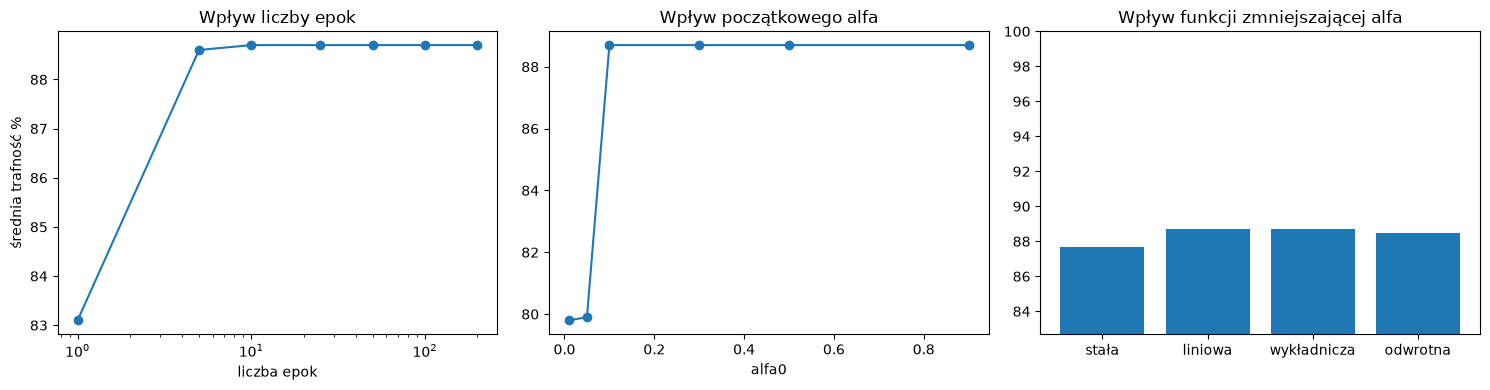

In [16]:
fig, osie = plt.subplots(1, 3, figsize=(15, 4))

osie[0].plot(tab_epoki["epoki"], tab_epoki["średnia trafność %"], marker="o")
osie[0].set_xscale("log")
osie[0].set_xlabel("liczba epok")
osie[0].set_ylabel("średnia trafność %")
osie[0].set_title("Wpływ liczby epok")

osie[1].plot(tab_alfa["alfa0"], tab_alfa["średnia trafność %"], marker="o")
osie[1].set_xlabel("alfa0")
osie[1].set_title("Wpływ początkowego alfa")

osie[2].bar(tab_funkcje["funkcja"], tab_funkcje["średnia trafność %"])
osie[2].set_ylim(min(tab_funkcje["średnia trafność %"]) - 5, 100)
osie[2].set_title("Wpływ funkcji zmniejszającej alfa")

plt.tight_layout()
plt.show()

### 6.5 Pełna siatka (wszystkie kombinacje)

In [18]:
wyniki = []
for nazwa in funkcje_alfa:
    for a0 in [0.1, 0.5, 0.9]:
        for epoki in [10, 50, 100]:
            sr, mn, mx = eksperyment(epoki, a0, funkcje_alfa[nazwa], powtorzenia=5)
            wyniki.append([nazwa, a0, epoki, round(sr * 100, 1)])

siatka = pd.DataFrame(wyniki, columns=["funkcja", "alfa0", "epoki", "średnia trafność %"])
siatka.sort_values("średnia trafność %", ascending=False).head(10)

,funkcja,alfa0,epoki,średnia trafność %
1,stała,0.1,50,89.1
31,odwrotna,0.5,50,89.1
33,odwrotna,0.9,10,89.1
10,liniowa,0.1,50,88.7
29,odwrotna,0.1,100,88.7
28,odwrotna,0.1,50,88.7
23,wykładnicza,0.5,100,88.7
11,liniowa,0.1,100,88.7
15,liniowa,0.9,10,88.7
14,liniowa,0.5,100,88.7
